In [1]:
import pandas as pd
import numpy as np

admissions = pd.read_csv("admissions.csv")
patients = pd.read_csv("Patients.csv")  
icustays = pd.read_csv("icustays.csv")

In [3]:
print(admissions.head())
print(patients.head())
print(icustays.head())

   subject_id   hadm_id            admittime            dischtime deathtime  \
0    10000032  22595853  2180-05-06 22:23:00  2180-05-07 17:15:00       NaN   
1    10000032  22841357  2180-06-26 18:27:00  2180-06-27 18:49:00       NaN   
2    10000032  25742920  2180-08-05 23:44:00  2180-08-07 17:50:00       NaN   
3    10000032  29079034  2180-07-23 12:35:00  2180-07-25 17:55:00       NaN   
4    10000068  25022803  2160-03-03 23:16:00  2160-03-04 06:26:00       NaN   

   admission_type admit_provider_id      admission_location  \
0          URGENT            P49AFC  TRANSFER FROM HOSPITAL   
1        EW EMER.            P784FA          EMERGENCY ROOM   
2        EW EMER.            P19UTS          EMERGENCY ROOM   
3        EW EMER.            P06OTX          EMERGENCY ROOM   
4  EU OBSERVATION            P39NWO          EMERGENCY ROOM   

  discharge_location insurance language marital_status   race  \
0               HOME  Medicaid  English        WIDOWED  WHITE   
1               

In [5]:
print(admissions.columns)
print(patients.columns)
print(icustays.columns)

Index(['subject_id', 'hadm_id', 'admittime', 'dischtime', 'deathtime',
       'admission_type', 'admit_provider_id', 'admission_location',
       'discharge_location', 'insurance', 'language', 'marital_status', 'race',
       'edregtime', 'edouttime', 'hospital_expire_flag'],
      dtype='object')
Index(['subject_id', 'gender', 'anchor_age', 'anchor_year',
       'anchor_year_group', 'dod'],
      dtype='object')
Index(['subject_id', 'hadm_id', 'stay_id', 'first_careunit', 'last_careunit',
       'intime', 'outtime', 'los'],
      dtype='object')


In [7]:
preview = pd.read_csv("labevents.csv", nrows=100)
print(preview)

print(preview.columns)

    labevent_id  subject_id  hadm_id  specimen_id  itemid order_provider_id  \
0             1    10000032      NaN      2704548   50931            P69FQC   
1             2    10000032      NaN     36092842   51071            P69FQC   
2             3    10000032      NaN     36092842   51074            P69FQC   
3             4    10000032      NaN     36092842   51075            P69FQC   
4             5    10000032      NaN     36092842   51079            P69FQC   
..          ...         ...      ...          ...     ...               ...   
95           96    10000032      NaN     95700408   50861               NaN   
96           97    10000032      NaN     95700408   50862               NaN   
97           98    10000032      NaN     95700408   50863               NaN   
98           99    10000032      NaN     95700408   50868               NaN   
99          100    10000032      NaN     95700408   50878               NaN   

              charttime            storetime value 

In [9]:
admissions['admittime'] = pd.to_datetime(admissions['admittime'])
admissions['dischtime'] = pd.to_datetime(admissions['dischtime'])
icustays['intime'] = pd.to_datetime(icustays['intime'])
icustays['outtime'] = pd.to_datetime(icustays['outtime'])
admissions = admissions.sort_values(by=['subject_id', 'admittime'])

In [11]:
admissions['next_admit'] = admissions.groupby('subject_id')['admittime'].shift(-1)
admissions['readmitted_30d'] = (admissions['next_admit'] - admissions['dischtime']).dt.days <= 30
admissions['readmitted_30d'] = admissions['readmitted_30d'].fillna(False).astype(int)

In [13]:
merged = admissions.merge(patients, on="subject_id", how="left")
merged = merged.merge(icustays, on="hadm_id", how="left")

if 'subject_id' not in merged.columns:
    merged['subject_id'] = admissions['subject_id']

merged['icu_los'] = (merged['outtime'] - merged['intime']).dt.total_seconds() / 86400
merged['age'] = merged['anchor_age']
merged['gender'] = merged['gender'].map({'M': 1, 'F': 0})  
merged['hospital_expire_flag'] = merged['hospital_expire_flag']

merged['icu_los'] = merged['icu_los'].fillna(-1)
merged['age'] = merged['age'].fillna(-1)
merged['gender'] = merged['gender'].fillna(-1)
merged['hospital_expire_flag'] = merged['hospital_expire_flag'].fillna(-1)

In [15]:

model_input = merged[['subject_id', 'hadm_id', 'stay_id', 'age', 'gender', 'icu_los', 'hospital_expire_flag', 'readmitted_30d']]


model_input.to_parquet('mimic4_cleaned.parquet')
model_input.to_csv('mimic4_cleaned.csv.gz', index=False, compression='gzip')

print("Preprocessing complete. Files saved: 'mimic4_cleaned.parquet' and 'mimic4_cleaned.csv.gz'")

d_labitems = pd.read_csv("d_labitems.csv")
print(d_labitems.head)
itemid_to_name = dict(zip(d_labitems['itemid'], d_labitems['label']))

Preprocessing complete. Files saved: 'mimic4_cleaned.parquet' and 'mimic4_cleaned.csv.gz'
<bound method NDFrame.head of       itemid                                label  fluid   category
0      50801           Alveolar-arterial Gradient  Blood  Blood Gas
1      50802                          Base Excess  Blood  Blood Gas
2      50803  Calculated Bicarbonate, Whole Blood  Blood  Blood Gas
3      50804                 Calculated Total CO2  Blood  Blood Gas
4      50805                    Carboxyhemoglobin  Blood  Blood Gas
...      ...                                  ...    ...        ...
1645   53186                                  MCH  Blood  Chemistry
1646   53187                                  PAN  Stool  Chemistry
1647   53188                          Lymphocytes  Blood  Chemistry
1648   53189                       Platelet Count  Blood  Chemistry
1649   53190                                 MXD%  Blood  Chemistry

[1650 rows x 4 columns]>


In [17]:
import glob


file_list = glob.glob("labevents_filtered_part_*.csv") 
labevents_filtered = pd.concat([pd.read_csv(file) for file in file_list], ignore_index=True)

print(f"Total lab rows after merging: {len(labevents_filtered)}")

agg = labevents_filtered.groupby(['hadm_id', 'itemid'])['valuenum'].agg(['mean', 'min', 'max', 'first']).reset_index()
agg.columns = ['hadm_id', 'itemid', 'mean', 'min', 'max', 'first']

C:\Users\syede\AppData\Local\Temp\ipykernel_16652\326790943.py:5: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  labevents_filtered = pd.concat([pd.read_csv(file) for file in file_list], ignore_index=True)
C:\Users\syede\AppData\Local\Temp\ipykernel_16652\326790943.py:5: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  labevents_filtered = pd.concat([pd.read_csv(file) for file in file_list], ignore_index=True)
C:\Users\syede\AppData\Local\Temp\ipykernel_16652\326790943.py:5: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  labevents_filtered = pd.concat([pd.read_csv(file) for file in file_list], ignore_index=True)
C:\Users\syede\AppData\Local\Temp\ipykernel_16652\326790943.py:5: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  labevents_filtered = pd.concat([pd.read_csv(file)

Total lab rows after merging: 21234338


In [19]:
melted = agg.melt(id_vars=['hadm_id', 'itemid'], var_name='stat', value_name='value')
melted['label'] = melted['itemid'].map(itemid_to_name)
melted['feature_name'] = melted['label'] + "_" + melted['stat']
melted = melted.groupby(['hadm_id', 'feature_name'])['value'].mean().reset_index()
pivoted = melted.pivot(index='hadm_id', columns='feature_name', values='value').reset_index()

In [20]:
cohort = pd.read_csv("mimic4_cleaned.csv.gz")

final = cohort.merge(pivoted, on='hadm_id', how='left')
final.to_csv("model_input_with_labs_named.csv.gz", index=False, compression='gzip')
print("Final dataset saved as model_input_with_labs_named.csv.gz")

Final dataset saved as model_input_with_labs_named.csv.gz


In [25]:
pd.read_csv("model_input_with_labs_named.csv.gz")

,subject_id,hadm_id,stay_id,age,gender,icu_los,hospital_expire_flag,readmitted_30d,Albumin_first,Albumin_max,...,Hematocrit_mean,Hematocrit_min,Lactate_first,Lactate_max,Lactate_mean,Lactate_min,Platelet Count_first,Platelet Count_max,Platelet Count_mean,Platelet Count_min
0,10000032.0,22595853,NaN,52,0,-1.000000,0,0,NaN,NaN,...,37.60,37.6,NaN,NaN,NaN,NaN,71.0,71.0,71.000000,71.0
1,10000032.0,22841357,NaN,52,0,-1.000000,0,1,2.7,2.7,...,35.50,35.5,NaN,NaN,NaN,NaN,137.0,137.0,137.000000,137.0
2,10000032.0,29079034,39553978.0,52,0,0.410266,0,1,3.8,3.8,...,33.45,32.1,NaN,NaN,NaN,NaN,94.0,95.0,94.500000,94.0
3,10000032.0,25742920,NaN,52,0,-1.000000,0,0,3.5,3.5,...,34.05,33.5,NaN,NaN,NaN,NaN,133.0,133.0,120.000000,107.0
4,10000068.0,25022803,NaN,19,0,-1.000000,0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
555239,NaN,29734428,NaN,46,0,-1.000000,0,0,3.2,3.2,...,32.70,28.7,1.9,1.9,1.90,1.9,507.0,507.0,369.736842,252.0
555240,NaN,25744818,36075953.0,46,0,1.790995,0,0,2.8,2.8,...,30.67,28.3,1.5,1.5,1.50,1.5,368.0,440.0,391.300000,324.0
555241,NaN,26071774,NaN,58,1,-1.000000,0,0,NaN,NaN,...,39.35,38.6,NaN,NaN,NaN,NaN,208.0,216.0,208.000000,198.0
555242,NaN,21033226,38978960.0,58,1,5.297766,1,0,4.3,4.3,...,36.60,33.0,0.9,7.0,3.66,0.9,272.0,321.0,277.333333,236.0


In [27]:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score
from sklearn.model_selection import GridSearchCV
import shap
import matplotlib.pyplot as plt

df = pd.read_csv("model_input_with_labs_named.csv.gz")
df_model = df.drop(columns=["subject_id", "hadm_id", "stay_id"], errors='ignore')
X = df_model.drop("readmitted_30d", axis=1)
y = df_model["readmitted_30d"]
X = X.fillna(-1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

ratio = y_train.value_counts()[0] / y_train.value_counts()[1]


xgb_model = XGBClassifier(
    use_label_encoder=False,
    eval_metric="logloss",
    scale_pos_weight=ratio  
)


param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2]
}


grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    scoring='roc_auc',  
    cv=5,  
    verbose=2,
    n_jobs=-1
)


grid_search.fit(X_train, y_train)


best_model = grid_search.best_estimator_

print("Best parameters found: ", grid_search.best_params_)

Fitting 5 folds for each of 18 candidates, totalling 90 fits


C:\Users\syede\anaconda3\Lib\site-packages\xgboost\training.py:183: UserWarning: [10:22:46] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best parameters found:  {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 200}


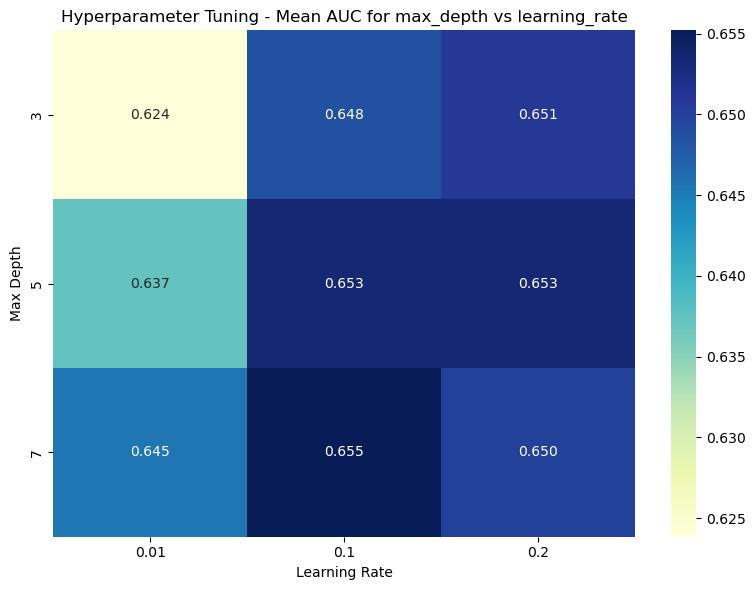

In [28]:

import matplotlib.pyplot as plt
import seaborn as sns

# Convert results to DataFrame
cv_results = pd.DataFrame(grid_search.cv_results_)

# Optional: Filter only the top scoring parameter sets
top_results = cv_results.sort_values(by="mean_test_score", ascending=False).head(20)

# Heatmap of mean_test_score for combinations of max_depth and learning_rate
pivot_table = cv_results.pivot_table(
    values="mean_test_score",
    index="param_max_depth",
    columns="param_learning_rate"
)

plt.figure(figsize=(8, 6))
sns.heatmap(pivot_table, annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("Hyperparameter Tuning - Mean AUC for max_depth vs learning_rate")
plt.xlabel("Learning Rate")
plt.ylabel("Max Depth")
plt.tight_layout()
plt.show()


In [31]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print("\n Classification Report:")
print(classification_report(y_test, y_pred))


 Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.67      0.75     88438
           1       0.30      0.55      0.39     22611

    accuracy                           0.64    111049
   macro avg       0.58      0.61      0.57    111049
weighted avg       0.74      0.64      0.68    111049



Brier Score: 0.22514768558352602


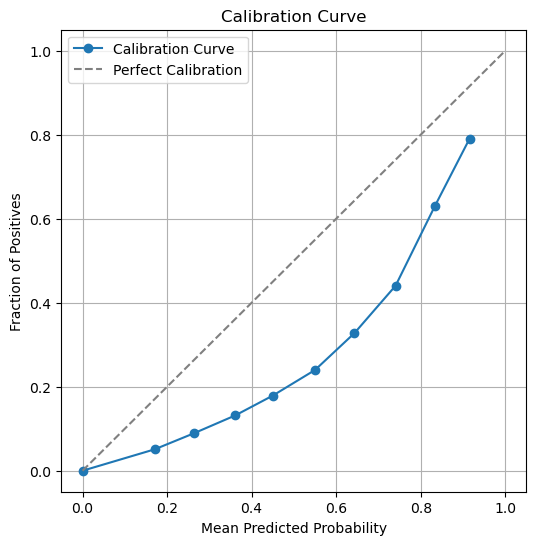

In [33]:
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# Brier score calculation
brier = brier_score_loss(y_test, y_prob)
print("Brier Score:", brier)

# Calibration curve
prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins=10)

# Plot
plt.figure(figsize=(6, 6))
plt.plot(prob_pred, prob_true, marker='o', label="Calibration Curve")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label="Perfect Calibration")
plt.title("Calibration Curve")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.legend()
plt.grid()
plt.show()

C:\Users\syede\anaconda3\Lib\site-packages\sklearn\calibration.py:333: UserWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.
  warnings.warn(


Calibrated Brier Score: 0.15394613528080306


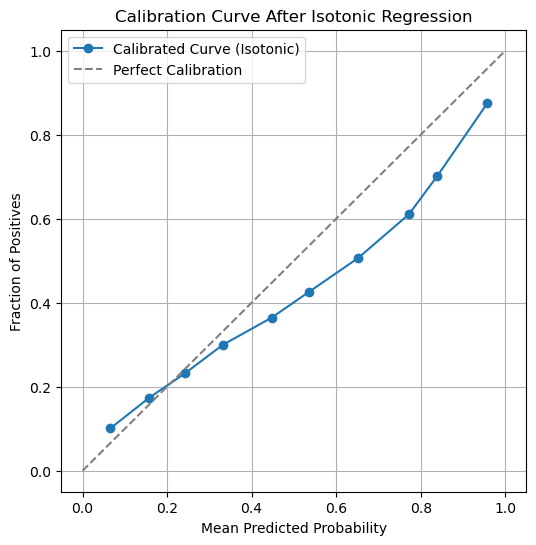

In [35]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

X_train_cal, X_cal, y_train_cal, y_cal = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

# ✅ Corrected line
calibrated_model = CalibratedClassifierCV(estimator=best_model, method='isotonic', cv='prefit')
calibrated_model.fit(X_cal, y_cal)

y_prob_calibrated = calibrated_model.predict_proba(X_test)[:, 1]

cal_brier = brier_score_loss(y_test, y_prob_calibrated)
print("Calibrated Brier Score:", cal_brier)

prob_true, prob_pred = calibration_curve(y_test, y_prob_calibrated, n_bins=10)

plt.figure(figsize=(6, 6))
plt.plot(prob_pred, prob_true, marker='o', label="Calibrated Curve (Isotonic)")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label="Perfect Calibration")
plt.title("Calibration Curve After Isotonic Regression")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.legend()
plt.grid()
plt.show()


In [37]:
print(" Accuracy:", accuracy_score(y_test, y_pred))
print(" AUC:", roc_auc_score(y_test, y_prob))

 Accuracy: 0.6438329025925492
 AUC: 0.6578527617528049


In [39]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from xgboost import XGBClassifier
import numpy as np
import pandas as pd

# Extract tuned parameters
best_params = best_model.get_params()

# Set up cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model_cv = XGBClassifier(**best_params)

# Store results
cv_results = {metric: [] for metric in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']}

# Run manual CV loop
for train_idx, test_idx in cv.split(X, y):
    X_train_cv, X_test_cv = X.iloc[train_idx], X.iloc[test_idx]
    y_train_cv, y_test_cv = y.iloc[train_idx], y.iloc[test_idx]

    model_cv.fit(X_train_cv, y_train_cv)
    y_pred = model_cv.predict(X_test_cv)
    y_prob = model_cv.predict_proba(X_test_cv)[:, 1]

    cv_results['accuracy'].append(accuracy_score(y_test_cv, y_pred))
    cv_results['precision'].append(precision_score(y_test_cv, y_pred, zero_division=0))
    cv_results['recall'].append(recall_score(y_test_cv, y_pred))
    cv_results['f1'].append(f1_score(y_test_cv, y_pred))

    try:
        auc = roc_auc_score(y_test_cv, y_prob)
        cv_results['roc_auc'].append(auc)
    except ValueError:
        cv_results['roc_auc'].append(np.nan)

# Summarize results
cv_summary = pd.DataFrame({
    metric: [np.nanmean(scores), np.nanstd(scores)]
    for metric, scores in cv_results.items()
}, index=["Mean", "Std"])

display(cv_summary)


C:\Users\syede\anaconda3\Lib\site-packages\xgboost\training.py:183: UserWarning: [10:25:26] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\syede\anaconda3\Lib\site-packages\xgboost\training.py:183: UserWarning: [10:25:40] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\syede\anaconda3\Lib\site-packages\xgboost\training.py:183: UserWarning: [10:25:56] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\syede\anaconda3\Lib\site-packages\xgboost\training.py:183: UserWarning: [10:26:11] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtr

,accuracy,precision,recall,f1,roc_auc
Mean,0.645568,0.298882,0.550397,0.387395,0.657428
Std,0.001511,0.001708,0.002732,0.002063,0.002112


In [41]:
# RE-ASSIGN test set and regenerate predictions to ensure alignment
from sklearn.model_selection import train_test_split

# Use the same random state and stratify for consistency
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Regenerate predictions using the correct X_test
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

# Confirm alignment
print("Length of y_test:", len(y_test))
print("Length of y_pred:", len(y_pred))


Length of y_test: 111049
Length of y_pred: 111049


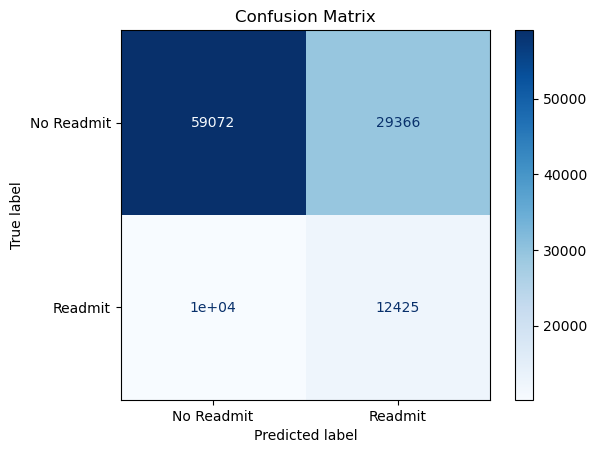

In [43]:
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc, precision_recall_curve


conf_matrix = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=["No Readmit", "Readmit"])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.grid(False)
plt.show()

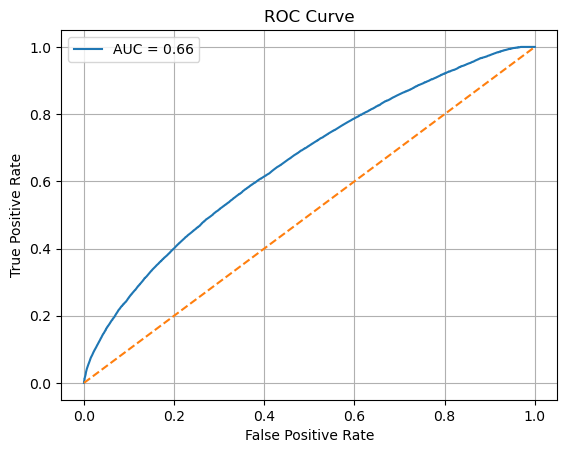

In [45]:

fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

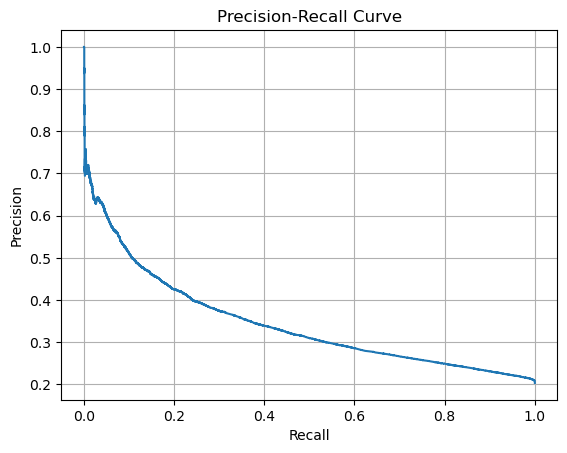

In [47]:

precision, recall, _ = precision_recall_curve(y_test, y_prob)
plt.figure()
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.grid(True)
plt.show()

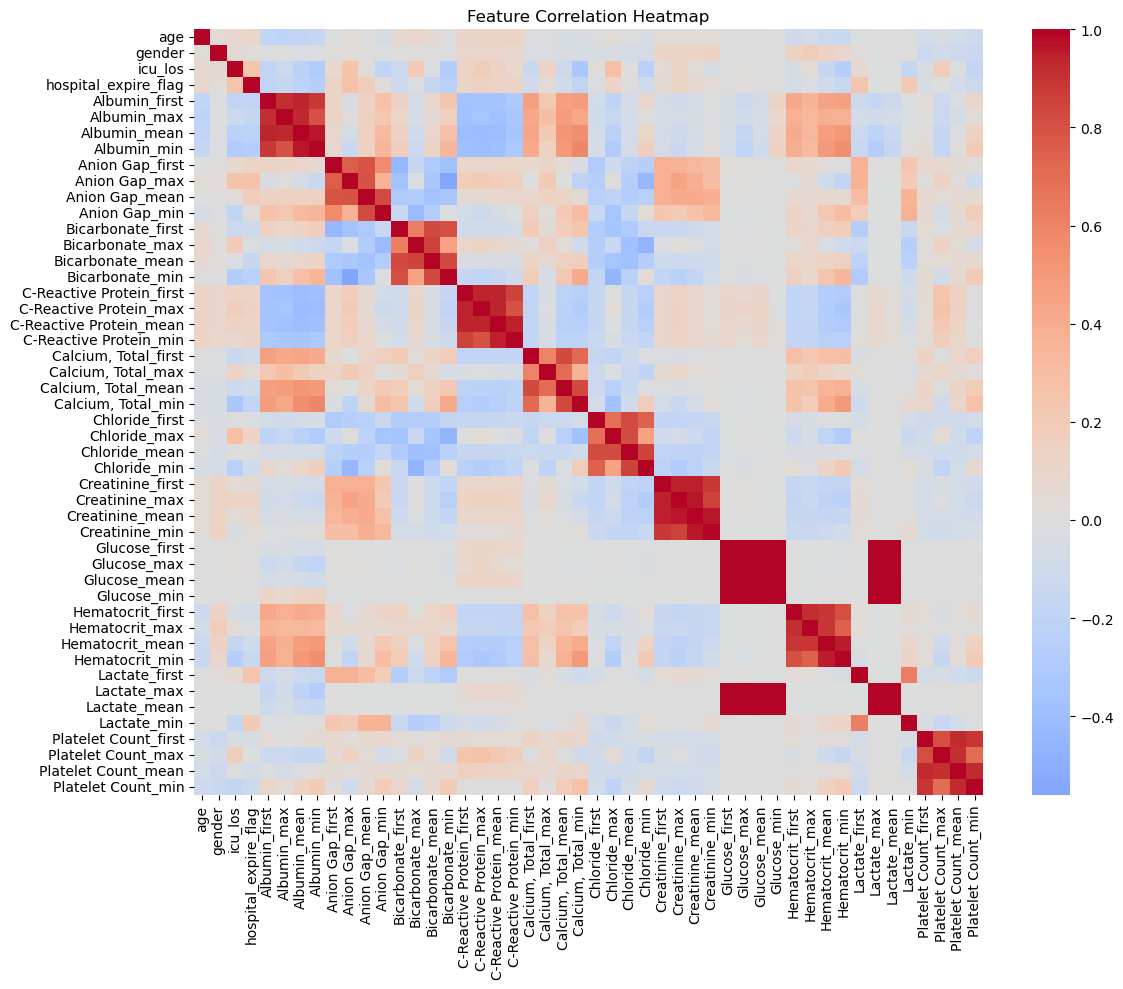

In [49]:

plt.figure(figsize=(12, 10))
corr = df_model.drop(columns="readmitted_30d").corr()
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

SHAP Summary Plot:


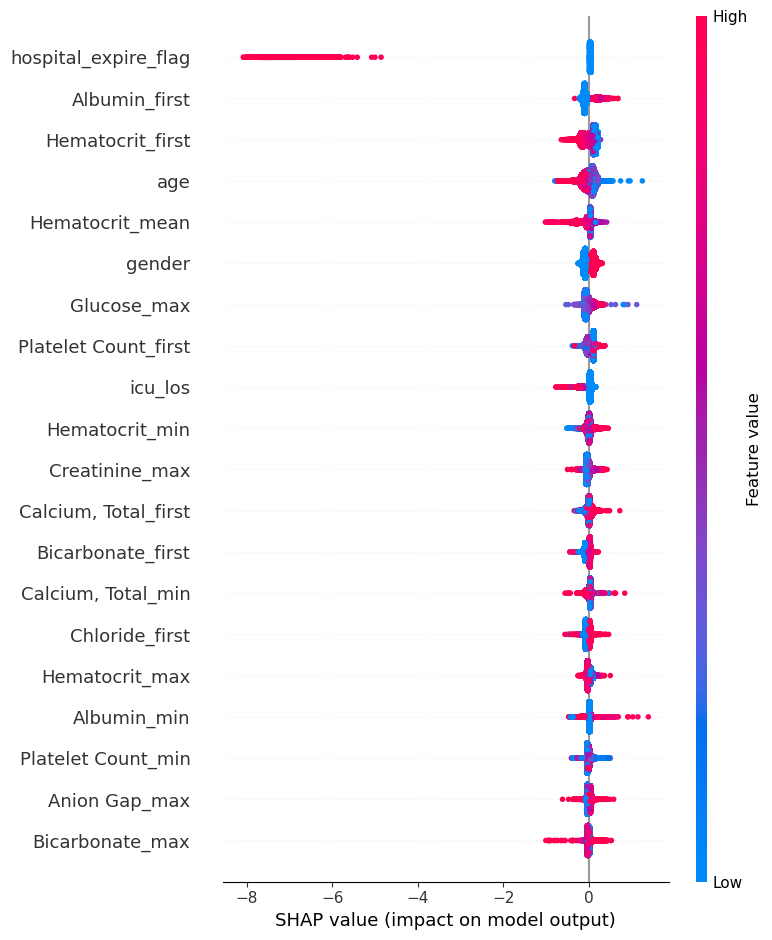

In [52]:
explainer = shap.Explainer(best_model)
shap_values = explainer(X_test)


print("SHAP Summary Plot:")
shap.summary_plot(shap_values, X_test)

SHAP Feature Importance (bar):


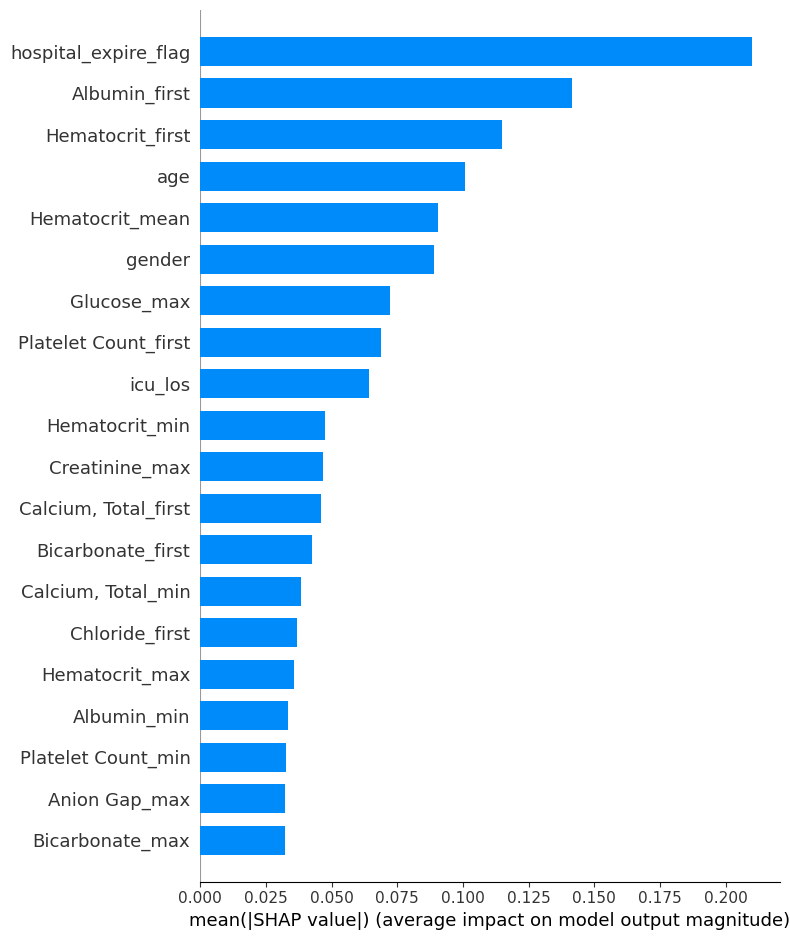

In [53]:
print("SHAP Feature Importance (bar):")
shap.summary_plot(shap_values, X_test, plot_type="bar")

In [54]:
!pip install lime
from lime.lime_tabular import LimeTabularExplainer
lime_explainer = LimeTabularExplainer(X_train.values, feature_names=X_train.columns.tolist(), class_names=['No Readmit', 'Readmit'], mode='classification')
sample = X_test.iloc[0].values
exp = lime_explainer.explain_instance(sample, best_model.predict_proba, num_features=10)
exp.show_in_notebook(show_table=True, show_all=False)

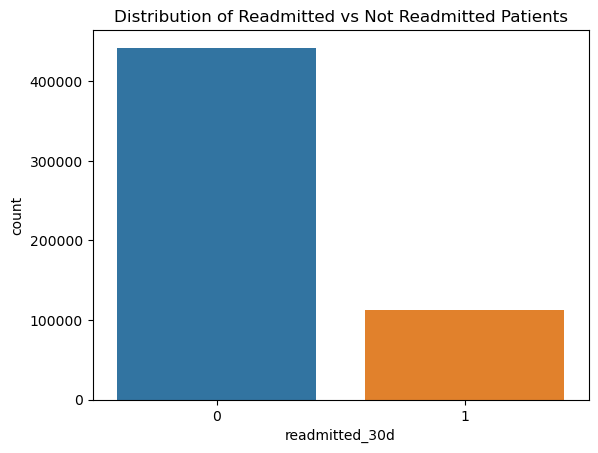

In [56]:
sns.countplot(data=df, x='readmitted_30d')
plt.title("Distribution of Readmitted vs Not Readmitted Patients")
plt.show()


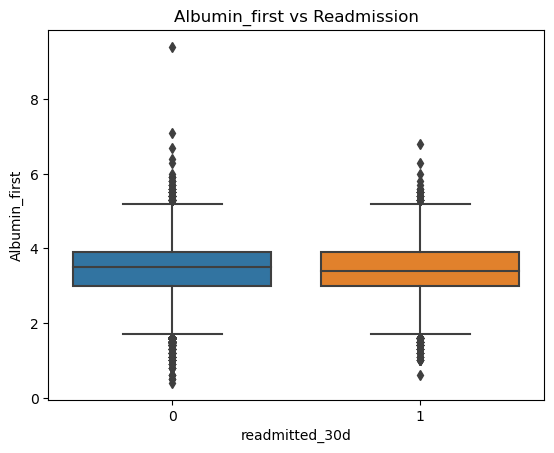

In [57]:
import seaborn as sns
sns.boxplot(data=df, x="readmitted_30d", y="Albumin_first")
plt.title("Albumin_first vs Readmission")
plt.show()


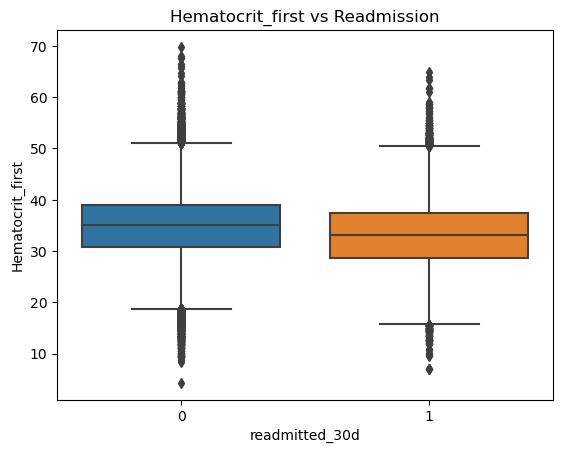

In [58]:
sns.boxplot(data=df, x="readmitted_30d", y="Hematocrit_first")
plt.title("Hematocrit_first vs Readmission")
plt.show()

Supplementary Analysis

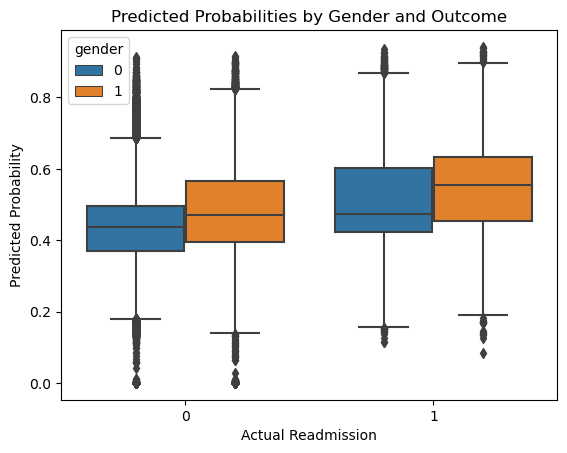

In [65]:
# Example: Compare predicted probability distributions by gender
sns.boxplot(x=y_test, y=y_prob, hue=X_test["gender"])
plt.title("Predicted Probabilities by Gender and Outcome")
plt.xlabel("Actual Readmission")
plt.ylabel("Predicted Probability")
plt.show()


In [67]:
from sklearn.metrics import precision_recall_fscore_support

thresholds = np.arange(0.1, 0.9, 0.1)
for t in thresholds:
    y_thresh = (y_prob >= t).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(y_test, y_thresh, average='binary')
    print(f"Threshold: {t:.1f} | Precision: {p:.2f} | Recall: {r:.2f} | F1: {f1:.2f}")


Threshold: 0.1 | Precision: 0.21 | Recall: 1.00 | F1: 0.35
Threshold: 0.2 | Precision: 0.21 | Recall: 1.00 | F1: 0.35
Threshold: 0.3 | Precision: 0.22 | Recall: 0.98 | F1: 0.35
Threshold: 0.4 | Precision: 0.24 | Recall: 0.84 | F1: 0.38
Threshold: 0.5 | Precision: 0.30 | Recall: 0.55 | F1: 0.39
Threshold: 0.6 | Precision: 0.38 | Recall: 0.29 | F1: 0.33
Threshold: 0.7 | Precision: 0.48 | Recall: 0.12 | F1: 0.20
Threshold: 0.8 | Precision: 0.64 | Recall: 0.03 | F1: 0.07


In [69]:
from sklearn.metrics import average_precision_score
pr_auc = average_precision_score(y_test, y_prob)
print("PR AUC:", pr_auc)


PR AUC: 0.3444075180784596


In [71]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
y_lr = lr.predict_proba(X_test)[:, 1]
print("Logistic AUC:", roc_auc_score(y_test, y_lr))


Logistic AUC: 0.6249920463190771


C:\Users\syede\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
from sklearn.utils import resample

auc_scores = []
for _ in range(1000):
    idx = resample(np.arange(len(y_test)), replace=True)
    if len(np.unique(y_test.iloc[idx])) == 1:
        continue
    auc_scores.append(roc_auc_score(y_test.iloc[idx], y_prob[idx]))

print("AUC 95% CI:", np.percentile(auc_scores, [2.5, 97.5]))
